# Yahtzee clásico: máquina contra máquina con decisiones por Montecarlo

Dos jugadores controlados por la máquina juegan Yahtzee con las reglas clásicas completas
(13 categorías, bono superior, bonos Yahtzee y regla de comodín). No hay intervención humana.

**Cómo usarlo:** ejecute todas las celdas en orden (*Entorno de ejecución → Ejecutar todas*).

- La celda de **parámetros** fija la semilla. La misma semilla reproduce exactamente los mismos resultados; otra semilla produce partidas distintas.
- La sección 3 juega **una partida narrada**.
- La sección 4 hace el **análisis de Montecarlo** completo (unos 15 minutos con los tamaños por defecto; reduzca los tamaños en la celda de parámetros para una prueba rápida).

In [1]:
import time
from itertools import combinations_with_replacement, product

import numpy as np
from statistics import NormalDist
import math
import matplotlib.pyplot as plt

# ===============================
# Parámetros
# ===============================
SEMILLA = 2026                 # semilla maestra del análisis de Montecarlo
SEMILLA_PARTIDA_EJEMPLO = 42   # semilla de la partida narrada
SIMULACIONES = 100             # muestras de Montecarlo por estimación dentro del agente

TURNOS_CALIBRACION = 1000      # turnos por categoría para estimar la línea base
PARTIDAS_PRINCIPAL = 2000
PARTIDAS_SENSIBILIDAD = 300
PARTIDAS_ENFRENTAMIENTO = 500
PARTIDAS_POR_SEMILLA = 200

## 1. Motor del juego y agente de Montecarlo

In [2]:
# ============================================================
# 1. Constantes del juego
# ============================================================
CATEGORIAS = [
    "unos", "doses", "treses", "cuatros", "cincos", "seises",
    "trio", "poker", "full", "escalera_corta", "escalera_larga",
    "yahtzee", "azar",
]
NUMERO_CATEGORIAS = 13
INDICE_TRIO = 6
INDICE_POKER = 7
INDICE_FULL = 8
INDICE_ESCALERA_CORTA = 9
INDICE_ESCALERA_LARGA = 10
INDICE_YAHTZEE = 11
INDICE_AZAR = 12
CATEGORIAS_SUPERIORES = [0, 1, 2, 3, 4, 5]
CATEGORIAS_INFERIORES = [6, 7, 8, 9, 10, 11, 12]

UMBRAL_BONO_SUPERIOR = 63
PUNTOS_BONO_SUPERIOR = 35
PUNTOS_BONO_YAHTZEE = 100
NUMERO_DADOS = 5
NUMERO_CARAS = 6
NUMERO_RONDAS = 13

# Peso heurístico que se suma a una casilla superior cuando el puntaje
# alcanza el "par" (3 dados de esa cara), que es lo que lleva al bono de 63.
PESO_PAR_SUPERIOR = PUNTOS_BONO_SUPERIOR / 6

In [3]:
# ============================================================
# 2. Puntuación de una mano (a partir de sus conteos por cara)
# ============================================================
def puntuar_conteos(conteos):
    """Devuelve los 13 puntajes "base" (sin reglas de comodín) de una mano.

    conteos[i] = cuántos dados muestran la cara i+1.
    """
    puntajes = np.zeros(NUMERO_CATEGORIAS)
    suma_dados = 0
    for cara in range(NUMERO_CARAS):
        suma_dados = suma_dados + (cara + 1) * conteos[cara]
        puntajes[cara] = (cara + 1) * conteos[cara]

    maximo_iguales = max(conteos)
    if maximo_iguales >= 3:
        puntajes[INDICE_TRIO] = suma_dados
    if maximo_iguales >= 4:
        puntajes[INDICE_POKER] = suma_dados

    conteos_no_nulos = sorted([c for c in conteos if c > 0])
    if conteos_no_nulos == [2, 3]:
        puntajes[INDICE_FULL] = 25

    caras_presentes = set()
    for cara in range(NUMERO_CARAS):
        if conteos[cara] > 0:
            caras_presentes.add(cara + 1)

    escaleras_cortas = [{1, 2, 3, 4}, {2, 3, 4, 5}, {3, 4, 5, 6}]
    for escalera in escaleras_cortas:
        if escalera.issubset(caras_presentes):
            puntajes[INDICE_ESCALERA_CORTA] = 30

    escaleras_largas = [{1, 2, 3, 4, 5}, {2, 3, 4, 5, 6}]
    for escalera in escaleras_largas:
        if escalera.issubset(caras_presentes):
            puntajes[INDICE_ESCALERA_LARGA] = 40

    if maximo_iguales == 5:
        puntajes[INDICE_YAHTZEE] = 50

    puntajes[INDICE_AZAR] = suma_dados
    return puntajes

In [4]:
# ============================================================
# 3. Tablas precalculadas
#    - 252 manos distintas (multiconjuntos de 5 dados)
#    - 462 conservaciones distintas (multiconjuntos de 0 a 5 dados)
#    Cada multiconjunto se codifica por sus conteos en base 6.
# ============================================================
POTENCIAS_BASE_6 = np.array([6 ** i for i in range(NUMERO_CARAS)])


def conteos_de_dados(lista_dados):
    conteos = np.zeros(NUMERO_CARAS, dtype=int)
    for dado in lista_dados:
        conteos[dado - 1] = conteos[dado - 1] + 1
    return conteos


# Manos (multiconjuntos de exactamente 5 dados)
LISTA_MANOS = list(combinations_with_replacement(range(1, 7), NUMERO_DADOS))
CONTEOS_MANOS = np.array([conteos_de_dados(mano) for mano in LISTA_MANOS])
NUMERO_MANOS = len(LISTA_MANOS)  # 252
CODIGO_A_MANO = np.full(6 ** NUMERO_CARAS, -1, dtype=int)
for indice_mano in range(NUMERO_MANOS):
    codigo = int(CONTEOS_MANOS[indice_mano] @ POTENCIAS_BASE_6)
    CODIGO_A_MANO[codigo] = indice_mano

PUNTAJES_BASE_MANOS = np.array([puntuar_conteos(c) for c in CONTEOS_MANOS])
MANOS_YAHTZEE = [i for i in range(NUMERO_MANOS) if CONTEOS_MANOS[i].max() == 5]

# Conservaciones (multiconjuntos de 0 a 5 dados)
LISTA_CONSERVACIONES = []
for tamano in range(NUMERO_DADOS + 1):
    for conservacion in combinations_with_replacement(range(1, 7), tamano):
        LISTA_CONSERVACIONES.append(conservacion)
CONTEOS_CONSERVACIONES = np.array([conteos_de_dados(c) for c in LISTA_CONSERVACIONES])
TAMANO_CONSERVACIONES = CONTEOS_CONSERVACIONES.sum(axis=1)
NUMERO_CONSERVACIONES = len(LISTA_CONSERVACIONES)  # 462
CODIGO_A_CONSERVACION = np.full(6 ** NUMERO_CARAS, -1, dtype=int)
for indice_conservacion in range(NUMERO_CONSERVACIONES):
    codigo = int(CONTEOS_CONSERVACIONES[indice_conservacion] @ POTENCIAS_BASE_6)
    CODIGO_A_CONSERVACION[codigo] = indice_conservacion

CONSERVACIONES_POR_TAMANO = []
for tamano in range(NUMERO_DADOS + 1):
    CONSERVACIONES_POR_TAMANO.append(np.where(TAMANO_CONSERVACIONES == tamano)[0])

# Para cada mano: las conservaciones posibles (sub-multiconjuntos), a lo sumo 32.
SUBCONSERVACIONES_POR_MANO = []
for indice_mano in range(NUMERO_MANOS):
    conteos_mano = CONTEOS_MANOS[indice_mano]
    rangos = [range(conteos_mano[cara] + 1) for cara in range(NUMERO_CARAS)]
    indices = []
    for subconteo in product(*rangos):
        codigo = int(np.array(subconteo) @ POTENCIAS_BASE_6)
        indices.append(CODIGO_A_CONSERVACION[codigo])
    SUBCONSERVACIONES_POR_MANO.append(np.array(indices))

# Matriz rellena (252 x 32) para calcular máximos de forma vectorizada.
MATRIZ_SUBCONSERVACIONES = np.zeros((NUMERO_MANOS, 32), dtype=int)
for indice_mano in range(NUMERO_MANOS):
    indices = SUBCONSERVACIONES_POR_MANO[indice_mano]
    MATRIZ_SUBCONSERVACIONES[indice_mano, :] = indices[0]  # relleno con un índice válido
    MATRIZ_SUBCONSERVACIONES[indice_mano, : len(indices)] = indices

# Mano que resulta de "conservar los 5 dados" (para conservaciones de tamaño 5)
CONSERVACION_A_MANO = np.full(NUMERO_CONSERVACIONES, -1, dtype=int)
for indice_conservacion in CONSERVACIONES_POR_TAMANO[NUMERO_DADOS]:
    codigo = int(CONTEOS_CONSERVACIONES[indice_conservacion] @ POTENCIAS_BASE_6)
    CONSERVACION_A_MANO[indice_conservacion] = CODIGO_A_MANO[codigo]


def indice_de_mano(dados):
    codigo = int(conteos_de_dados(dados) @ POTENCIAS_BASE_6)
    return CODIGO_A_MANO[codigo]

In [5]:
# ============================================================
# 4. Estado de un jugador y reglas oficiales de anotación
# ============================================================
class Jugador:
    def __init__(self, nombre, simulaciones, peso_par_superior=PESO_PAR_SUPERIOR):
        self.nombre = nombre
        self.simulaciones = simulaciones  # muestras de Montecarlo por estimación
        self.peso_par_superior = peso_par_superior
        self.puntajes = [None] * NUMERO_CATEGORIAS
        self.bonos_yahtzee = 0

    def categorias_abiertas(self):
        abiertas = []
        for indice in range(NUMERO_CATEGORIAS):
            if self.puntajes[indice] is None:
                abiertas.append(indice)
        return abiertas

    def subtotal_superior(self):
        subtotal = 0
        for indice in CATEGORIAS_SUPERIORES:
            if self.puntajes[indice] is not None:
                subtotal = subtotal + self.puntajes[indice]
        return subtotal

    def tiene_bono_superior(self):
        return self.subtotal_superior() >= UMBRAL_BONO_SUPERIOR

    def total(self):
        suma = 0
        for valor in self.puntajes:
            if valor is not None:
                suma = suma + valor
        if self.tiene_bono_superior():
            suma = suma + PUNTOS_BONO_SUPERIOR
        suma = suma + PUNTOS_BONO_YAHTZEE * self.bonos_yahtzee
        return suma


def opciones_legales(jugador, indice_mano):
    """Lista de (categoria, puntos_en_casilla, puntos_de_bono) legales.

    Aplica la regla oficial de comodín ("Joker", forzado) cuando se saca un
    Yahtzee y la casilla Yahtzee ya está ocupada.
    """
    puntajes_base = PUNTAJES_BASE_MANOS[indice_mano]
    abiertas = jugador.categorias_abiertas()
    es_yahtzee = indice_mano in MANOS_YAHTZEE
    casilla_yahtzee_ocupada = jugador.puntajes[INDICE_YAHTZEE] is not None

    if not (es_yahtzee and casilla_yahtzee_ocupada):
        opciones = []
        for categoria in abiertas:
            opciones.append((categoria, puntajes_base[categoria], 0))
        return opciones

    # --- Regla de comodín ---
    bono = 0
    if jugador.puntajes[INDICE_YAHTZEE] == 50:
        bono = PUNTOS_BONO_YAHTZEE
    cara = int(np.argmax(CONTEOS_MANOS[indice_mano]))  # 0..5
    suma_dados = 5 * (cara + 1)

    # (a) Si la casilla superior de esa cara está libre, es obligatoria.
    if cara in abiertas:
        return [(cara, suma_dados, bono)]

    # (b) Si no, cualquier casilla inferior libre, con su valor completo.
    valores_comodin = {
        INDICE_TRIO: suma_dados, INDICE_POKER: suma_dados, INDICE_FULL: 25,
        INDICE_ESCALERA_CORTA: 30, INDICE_ESCALERA_LARGA: 40, INDICE_AZAR: suma_dados,
    }
    opciones = []
    for categoria in abiertas:
        if categoria in valores_comodin:
            opciones.append((categoria, valores_comodin[categoria], bono))
    if len(opciones) > 0:
        return opciones

    # (c) Si no, cualquier casilla superior libre, con 0 puntos.
    for categoria in abiertas:
        opciones.append((categoria, 0, bono))
    return opciones

In [6]:
# ============================================================
# 5. Función de utilidad del agente
# ============================================================
def utilidad_de_opcion(jugador, categoria, puntos, bono, linea_base):
    """Utilidad = puntos ganados - costo de oportunidad de gastar la casilla."""
    utilidad = puntos + bono - linea_base[categoria]
    if categoria in CATEGORIAS_SUPERIORES and not jugador.tiene_bono_superior():
        cara = categoria + 1
        if puntos >= 3 * cara:
            utilidad = utilidad + jugador.peso_par_superior
    return utilidad


def utilidades_de_todas_las_manos(jugador, linea_base):
    """Utilidad de anotar ahora cada una de las 252 manos (mejor opción legal)."""
    utilidades = np.full(NUMERO_MANOS, -np.inf)
    sin_bono_superior = not jugador.tiene_bono_superior()

    # Cálculo vectorizado para las manos normales
    for categoria in jugador.categorias_abiertas():
        columna = PUNTAJES_BASE_MANOS[:, categoria] - linea_base[categoria]
        if categoria in CATEGORIAS_SUPERIORES and sin_bono_superior:
            cara = categoria + 1
            alcanza_par = PUNTAJES_BASE_MANOS[:, categoria] >= 3 * cara
            columna = columna + jugador.peso_par_superior * alcanza_par
        utilidades = np.maximum(utilidades, columna)

    # Las 6 manos Yahtzee se recalculan con las reglas exactas (comodín)
    for indice_mano in MANOS_YAHTZEE:
        mejor = -np.inf
        for categoria, puntos, bono in opciones_legales(jugador, indice_mano):
            valor = utilidad_de_opcion(jugador, categoria, puntos, bono, linea_base)
            if valor > mejor:
                mejor = valor
        utilidades[indice_mano] = mejor
    return utilidades

In [7]:
# ============================================================
# 6. Núcleo de Montecarlo
# ============================================================
def contar_caras(tiradas):
    """tiradas: arreglo (..., k) con valores 1..6 -> conteos (..., 6)."""
    conteos = []
    for cara in range(1, NUMERO_CARAS + 1):
        conteos.append((tiradas == cara).sum(axis=-1))
    return np.stack(conteos, axis=-1)


def estimar_valor_por_conservacion(valor_por_mano, simulaciones, generador):
    """Estimación de Montecarlo de E[ valor_por_mano(mano siguiente) ] para cada
    una de las 462 conservaciones posibles.

    Para una conservación con k dados, se simulan `simulaciones` relanzamientos
    de los 5-k dados restantes y se promedia el valor de la mano resultante.
    """
    estimaciones = np.zeros(NUMERO_CONSERVACIONES)
    for tamano in range(NUMERO_DADOS + 1):
        indices = CONSERVACIONES_POR_TAMANO[tamano]
        dados_a_lanzar = NUMERO_DADOS - tamano

        if dados_a_lanzar == 0:
            # No se lanza nada: el valor es exactamente el de la mano conservada.
            estimaciones[indices] = valor_por_mano[CONSERVACION_A_MANO[indices]]
            continue

        tiradas = generador.integers(1, 7, size=(len(indices), simulaciones, dados_a_lanzar))
        conteos_tiradas = contar_caras(tiradas)
        conteos_finales = conteos_tiradas + CONTEOS_CONSERVACIONES[indices][:, None, :]
        codigos = conteos_finales @ POTENCIAS_BASE_6
        manos_resultantes = CODIGO_A_MANO[codigos]
        estimaciones[indices] = valor_por_mano[manos_resultantes].mean(axis=1)
    return estimaciones


def planificar_turno(jugador, linea_base, generador):
    """Calcula, por Montecarlo, las tablas de valor del turno.

    V0(mano)        = utilidad de anotar la mano ahora.
    V1(conservación)= E[ V0(mano tras 1 relanzamiento) ]           (MC)
    M1(mano)        = max sobre conservaciones de V1
    V2(conservación)= E[ M1(mano tras 1 relanzamiento) ]           (MC)
    """
    simulaciones = jugador.simulaciones
    valor_anotar = utilidades_de_todas_las_manos(jugador, linea_base)
    valor_una_tirada = estimar_valor_por_conservacion(valor_anotar, simulaciones, generador)
    mejor_valor_una_tirada = valor_una_tirada[MATRIZ_SUBCONSERVACIONES].max(axis=1)
    valor_dos_tiradas = estimar_valor_por_conservacion(mejor_valor_una_tirada, simulaciones, generador)
    return valor_una_tirada, valor_dos_tiradas


def elegir_conservacion(dados, tabla_valores):
    """Devuelve la conservación (lista de dados) de mayor valor estimado."""
    indice_mano = indice_de_mano(dados)
    candidatas = SUBCONSERVACIONES_POR_MANO[indice_mano]
    mejor_indice = candidatas[0]
    mejor_valor = tabla_valores[mejor_indice]
    for indice in candidatas:
        if tabla_valores[indice] > mejor_valor:
            mejor_valor = tabla_valores[indice]
            mejor_indice = indice
    return list(LISTA_CONSERVACIONES[mejor_indice])


def elegir_categoria(jugador, dados, linea_base):
    indice_mano = indice_de_mano(dados)
    mejor_opcion = None
    mejor_utilidad = -np.inf
    for categoria, puntos, bono in opciones_legales(jugador, indice_mano):
        valor = utilidad_de_opcion(jugador, categoria, puntos, bono, linea_base)
        if valor > mejor_utilidad:
            mejor_utilidad = valor
            mejor_opcion = (categoria, puntos, bono)
    return mejor_opcion

In [8]:
# ============================================================
# 7. Flujo de un turno y de una partida
# ============================================================
def lanzar(numero_dados, generador):
    return [int(x) for x in generador.integers(1, 7, size=numero_dados)]


def jugar_turno(jugador, linea_base, generador, contador_caras, verboso=False):
    valor_una_tirada, valor_dos_tiradas = planificar_turno(jugador, linea_base, generador)

    # Tirada 1
    dados = lanzar(NUMERO_DADOS, generador)
    for dado in dados:
        contador_caras[dado - 1] += 1
    tiradas_usadas = 1
    if verboso:
        print(f"  {jugador.nombre} | tirada 1: {sorted(dados)}")

    # Decisiones con 2 y 1 relanzamientos restantes
    for tabla in (valor_dos_tiradas, valor_una_tirada):
        conservados = elegir_conservacion(dados, tabla)
        if len(conservados) == NUMERO_DADOS:
            if verboso:
                print(f"  {jugador.nombre} | se planta con {sorted(dados)}")
            break
        nuevos = lanzar(NUMERO_DADOS - len(conservados), generador)
        for dado in nuevos:
            contador_caras[dado - 1] += 1
        dados = conservados + nuevos
        tiradas_usadas = tiradas_usadas + 1
        if verboso:
            print(f"  {jugador.nombre} | conserva {conservados} -> tirada {tiradas_usadas}: {sorted(dados)}")

    categoria, puntos, bono = elegir_categoria(jugador, dados, linea_base)
    jugador.puntajes[categoria] = puntos
    if bono > 0:
        jugador.bonos_yahtzee = jugador.bonos_yahtzee + 1
    if verboso:
        texto_bono = f" (+{bono} bono Yahtzee)" if bono > 0 else ""
        print(f"  {jugador.nombre} | anota {puntos:.0f} en '{CATEGORIAS[categoria]}'{texto_bono}. Total: {jugador.total():.0f}")
    return tiradas_usadas


def jugar_partida(generador, linea_base, simulaciones_j1, simulaciones_j2, verboso=False):
    jugadores = [Jugador("Jugador 1", simulaciones_j1), Jugador("Jugador 2", simulaciones_j2)]
    contador_caras = np.zeros(NUMERO_CARAS, dtype=int)
    tiradas_por_jugador = [0, 0]

    for ronda in range(1, NUMERO_RONDAS + 1):
        if verboso:
            print(f"--- Ronda {ronda} ---")
        for posicion in range(2):
            usadas = jugar_turno(jugadores[posicion], linea_base, generador, contador_caras, verboso)
            tiradas_por_jugador[posicion] += usadas

    resultado = {
        "totales": [jugadores[0].total(), jugadores[1].total()],
        "puntajes": [list(jugadores[0].puntajes), list(jugadores[1].puntajes)],
        "bono_superior": [jugadores[0].tiene_bono_superior(), jugadores[1].tiene_bono_superior()],
        "bonos_yahtzee": [jugadores[0].bonos_yahtzee, jugadores[1].bonos_yahtzee],
        "tiradas": tiradas_por_jugador,
        "caras": contador_caras,
    }
    if verboso:
        imprimir_marcador(jugadores)
    return resultado


def imprimir_marcador(jugadores):
    print("\n===== MARCADOR FINAL =====")
    print(f"{'Categoría':16s}" + "".join(f"{j.nombre:>12s}" for j in jugadores))
    for indice in range(NUMERO_CATEGORIAS):
        fila = f"{CATEGORIAS[indice]:16s}"
        for jugador in jugadores:
            fila = fila + f"{jugador.puntajes[indice]:>12.0f}"
        print(fila)
    print(f"{'bono superior':16s}" + "".join(f"{(35 if j.tiene_bono_superior() else 0):>12d}" for j in jugadores))
    print(f"{'bono yahtzee':16s}" + "".join(f"{100 * j.bonos_yahtzee:>12d}" for j in jugadores))
    print(f"{'TOTAL':16s}" + "".join(f"{j.total():>12.0f}" for j in jugadores))
    if jugadores[0].total() > jugadores[1].total():
        print("Ganador: Jugador 1")
    elif jugadores[1].total() > jugadores[0].total():
        print("Ganador: Jugador 2")
    else:
        print("Empate")

In [9]:
# ============================================================
# 8. Línea base (costo de oportunidad) estimada por Montecarlo
# ============================================================
def estimar_linea_base(generador, simulaciones, turnos_por_categoria):
    """Para cada categoría c se simulan muchos turnos en los que c es la única
    casilla abierta y el agente maximiza solo el puntaje de c. El promedio es el
    valor esperado de "dedicar un turno" a c, y se usa como costo de oportunidad.
    """
    linea_cero = np.zeros(NUMERO_CATEGORIAS)
    linea_base = np.zeros(NUMERO_CATEGORIAS)
    for categoria in range(NUMERO_CATEGORIAS):
        suma = 0.0
        for _ in range(turnos_por_categoria):
            # Sin ajuste del par superior: solo cuenta el puntaje bruto.
            jugador = Jugador("calibración", simulaciones, peso_par_superior=0.0)
            for otra in range(NUMERO_CATEGORIAS):
                if otra != categoria:
                    jugador.puntajes[otra] = 0
            jugador.puntajes[INDICE_YAHTZEE] = None if categoria == INDICE_YAHTZEE else 0
            contador = np.zeros(NUMERO_CARAS, dtype=int)
            jugar_turno(jugador, linea_cero, generador, contador)
            suma = suma + jugador.puntajes[categoria]
        linea_base[categoria] = suma / turnos_por_categoria
    return linea_base

## 2. Calibración y partida de ejemplo

La línea base (costo de oportunidad de cada categoría) se estima por Montecarlo y luego se juega una partida
narrada. Cambie `SEMILLA_PARTIDA_EJEMPLO` para ver otra partida.

In [10]:
generador_ejemplo = np.random.default_rng(SEMILLA_PARTIDA_EJEMPLO)
linea_base_ejemplo = estimar_linea_base(generador_ejemplo, SIMULACIONES, turnos_por_categoria=300)
print("Línea base estimada:")
for indice in range(NUMERO_CATEGORIAS):
    print(f"  {CATEGORIAS[indice]:16s} {linea_base_ejemplo[indice]:7.2f}")
print()
partida_ejemplo = jugar_partida(generador_ejemplo, linea_base_ejemplo, SIMULACIONES, SIMULACIONES, verboso=True)

Línea base estimada:
  unos                2.20
  doses               4.14
  treses              5.95
  cuatros             8.12
  cincos              9.92
  seises             12.52
  trio               16.08
  poker               5.20
  full               10.08
  escalera_corta     17.60
  escalera_larga      9.87
  yahtzee             2.00
  azar               23.18

--- Ronda 1 ---
  Jugador 1 | tirada 1: [2, 2, 4, 6, 6]
  Jugador 1 | conserva [6, 6] -> tirada 2: [2, 3, 3, 6, 6]
  Jugador 1 | conserva [3, 3] -> tirada 3: [1, 3, 3, 3, 6]
  Jugador 1 | anota 9 en 'treses'. Total: 9
  Jugador 2 | tirada 1: [1, 2, 3, 3, 4]
  Jugador 2 | conserva [1, 2, 3, 4] -> tirada 2: [1, 2, 2, 3, 4]
  Jugador 2 | conserva [1, 2, 3, 4] -> tirada 3: [1, 2, 3, 4, 6]
  Jugador 2 | anota 30 en 'escalera_corta'. Total: 30
--- Ronda 2 ---
  Jugador 1 | tirada 1: [1, 1, 4, 5, 5]
  Jugador 1 | conserva [4, 5] -> tirada 2: [1, 2, 4, 5, 5]
  Jugador 1 | conserva [2, 4, 5] -> tirada 3: [2, 4, 5, 5, 6]
  Jugado

## 3. Funciones del análisis de Montecarlo

In [11]:
# ------------------------------------------------------------
# Utilidades estadísticas
# ------------------------------------------------------------
def intervalo_confianza_media(datos, nivel=0.95):
    datos = np.asarray(datos, dtype=float)
    media = datos.mean()
    error_estandar = datos.std(ddof=1) / np.sqrt(len(datos))
    z = NormalDist().inv_cdf(0.5 + nivel / 2)
    return media, media - z * error_estandar, media + z * error_estandar


def intervalo_confianza_proporcion(exitos, total, nivel=0.95):
    p = exitos / total
    z = NormalDist().inv_cdf(0.5 + nivel / 2)
    error = z * np.sqrt(p * (1 - p) / total)
    return p, p - error, p + error


def correr_partidas(generador, linea_base, numero_partidas, simulaciones_j1, simulaciones_j2):
    resultados = []
    inicio = time.time()
    for _ in range(numero_partidas):
        resultados.append(jugar_partida(generador, linea_base, simulaciones_j1, simulaciones_j2))
    duracion = time.time() - inicio
    return resultados, duracion


def prueba_chi_cuadrado(observados):
    """Prueba chi-cuadrado de uniformidad (todas las categorías igual de probables).

    Devuelve (estadístico, valor p). El valor p es la cola superior de una
    chi-cuadrado con k - 1 grados de libertad, calculada con la función gamma
    incompleta regularizada (serie de potencias), sin librerías externas.
    """
    observados = np.asarray(observados, dtype=float)
    total = observados.sum()
    esperado = total / len(observados)
    estadistico = 0.0
    for valor in observados:
        estadistico = estadistico + (valor - esperado) ** 2 / esperado

    grados_libertad = len(observados) - 1
    a = grados_libertad / 2
    x = estadistico / 2
    # P(a, x) = x^a e^-x / Gamma(a+1) * sum_{n>=0} x^n / ((a+1)(a+2)...(a+n))
    termino = 1.0
    suma = 1.0
    for n in range(1, 500):
        termino = termino * x / (a + n)
        suma = suma + termino
        if termino < 1e-15 * suma:
            break
    gamma_inferior = math.exp(a * math.log(x) - x - math.lgamma(a + 1)) * suma
    valor_p = 1.0 - gamma_inferior
    return estadistico, valor_p

In [12]:
# ------------------------------------------------------------
# E1: validación contra probabilidades exactas
# ------------------------------------------------------------
def probabilidades_exactas_una_tirada():
    """Enumera las 6^5 = 7776 tiradas posibles."""
    conteo = {"yahtzee": 0, "escalera_larga": 0, "escalera_corta": 0, "full": 0, "poker": 0, "trio": 0}
    total = 0
    for tirada in product(range(1, 7), repeat=5):
        puntajes = puntuar_conteos(conteos_de_dados(tirada))
        total = total + 1
        if puntajes[INDICE_YAHTZEE] > 0:
            conteo["yahtzee"] += 1
        if puntajes[INDICE_ESCALERA_LARGA] > 0:
            conteo["escalera_larga"] += 1
        if puntajes[INDICE_ESCALERA_CORTA] > 0:
            conteo["escalera_corta"] += 1
        if puntajes[INDICE_FULL] > 0:
            conteo["full"] += 1
        if puntajes[INDICE_POKER] > 0:
            conteo["poker"] += 1
        if puntajes[INDICE_TRIO] > 0:
            conteo["trio"] += 1
    return {clave: valor / total for clave, valor in conteo.items()}, conteo, total


def probabilidad_exacta_yahtzee_tres_tiradas():
    """Política: conservar siempre el grupo más numeroso de caras iguales.
    Cadena de Markov sobre k = tamaño del grupo mayor (1..5), calculada por
    enumeración exacta de los relanzamientos."""
    # Distribución de k tras la primera tirada
    distribucion = np.zeros(6)
    for tirada in product(range(1, 7), repeat=5):
        distribucion[max(conteos_de_dados(tirada))] += 1
    distribucion = distribucion / 6 ** 5

    # Matriz de transición: con k dados iguales (cara 1) se relanzan 5-k
    transicion = np.zeros((6, 6))
    transicion[5, 5] = 1.0
    for k in range(1, 5):
        for relanzamiento in product(range(1, 7), repeat=5 - k):
            conteos = conteos_de_dados(relanzamiento)
            conteos[0] = conteos[0] + k
            transicion[k, max(conteos)] += 1
        transicion[k] = transicion[k] / 6 ** (5 - k)

    distribucion_final = distribucion @ transicion @ transicion
    return distribucion_final[5]


def simular_una_tirada(generador, numero_tiradas):
    tiradas = generador.integers(1, 7, size=(numero_tiradas, 5))
    conteos = contar_caras(tiradas)
    codigos = conteos @ POTENCIAS_BASE_6
    manos = CODIGO_A_MANO[codigos]
    puntajes = PUNTAJES_BASE_MANOS[manos]
    return {
        "yahtzee": (puntajes[:, INDICE_YAHTZEE] > 0).sum(),
        "escalera_larga": (puntajes[:, INDICE_ESCALERA_LARGA] > 0).sum(),
        "escalera_corta": (puntajes[:, INDICE_ESCALERA_CORTA] > 0).sum(),
        "full": (puntajes[:, INDICE_FULL] > 0).sum(),
        "poker": (puntajes[:, INDICE_POKER] > 0).sum(),
        "trio": (puntajes[:, INDICE_TRIO] > 0).sum(),
    }


def simular_yahtzee_tres_tiradas(generador, numero_turnos):
    conteos = contar_caras(generador.integers(1, 7, size=(numero_turnos, 5)))
    for _ in range(2):
        cara_mayor = conteos.argmax(axis=1)
        grupo_mayor = conteos.max(axis=1)
        nuevos_conteos = np.zeros_like(conteos)
        nuevos_conteos[np.arange(numero_turnos), cara_mayor] = grupo_mayor
        for k in range(1, 6):
            filas = np.where(grupo_mayor == k)[0]
            if k == 5 or len(filas) == 0:
                if k == 5:
                    nuevos_conteos[filas] = conteos[filas]
                continue
            relanzamiento = generador.integers(1, 7, size=(len(filas), 5 - k))
            nuevos_conteos[filas] = nuevos_conteos[filas] + contar_caras(relanzamiento)
        conteos = nuevos_conteos
    return int((conteos.max(axis=1) == 5).sum())

In [13]:
# ------------------------------------------------------------
# E3b: convergencia del estimador de valor de una conservación
# ------------------------------------------------------------
def valor_exacto_conservacion(utilidad_manos, conservados):
    faltantes = 5 - len(conservados)
    suma = 0.0
    for relanzamiento in product(range(1, 7), repeat=faltantes):
        suma = suma + utilidad_manos[indice_de_mano(list(conservados) + list(relanzamiento))]
    return suma / 6 ** faltantes


def estimar_conservacion(utilidad_manos, conservados, simulaciones, generador):
    faltantes = 5 - len(conservados)
    relanzamientos = generador.integers(1, 7, size=(simulaciones, faltantes))
    conteos = contar_caras(relanzamientos) + conteos_de_dados(conservados)
    manos = CODIGO_A_MANO[conteos @ POTENCIAS_BASE_6]
    return utilidad_manos[manos].mean()

In [14]:
# ------------------------------------------------------------
# Resumen de un lote de partidas
# ------------------------------------------------------------
def resumir(resultados):
    puntajes = []
    for r in resultados:
        puntajes.append(r["totales"][0])
        puntajes.append(r["totales"][1])
    puntajes = np.array(puntajes, dtype=float)

    victorias_j1 = sum(1 for r in resultados if r["totales"][0] > r["totales"][1])
    victorias_j2 = sum(1 for r in resultados if r["totales"][1] > r["totales"][0])
    empates = len(resultados) - victorias_j1 - victorias_j2

    bonos_superiores = sum(int(b) for r in resultados for b in r["bono_superior"])
    hojas_con_yahtzee = sum(1 for r in resultados for j in range(2) if r["puntajes"][j][INDICE_YAHTZEE] == 50)
    bonos_yahtzee = sum(b for r in resultados for b in r["bonos_yahtzee"])
    tiradas = sum(t for r in resultados for t in r["tiradas"])
    caras = np.sum([r["caras"] for r in resultados], axis=0)
    hojas = 2 * len(resultados)

    media, inferior, superior = intervalo_confianza_media(puntajes)
    promedio_por_categoria = []
    ceros_por_categoria = []
    for indice in range(NUMERO_CATEGORIAS):
        valores = [r["puntajes"][j][indice] for r in resultados for j in range(2)]
        promedio_por_categoria.append(float(np.mean(valores)))
        ceros_por_categoria.append(float(np.mean([v == 0 for v in valores])))

    return {
        "partidas": len(resultados),
        "hojas": hojas,
        "media": media, "ic_inferior": inferior, "ic_superior": superior,
        "desviacion": float(puntajes.std(ddof=1)),
        "mediana": float(np.median(puntajes)),
        "minimo": float(puntajes.min()), "maximo": float(puntajes.max()),
        "percentil_5": float(np.percentile(puntajes, 5)),
        "percentil_95": float(np.percentile(puntajes, 95)),
        "victorias_j1": victorias_j1, "victorias_j2": victorias_j2, "empates": empates,
        "tasa_bono_superior": bonos_superiores / hojas,
        "tasa_yahtzee_50": hojas_con_yahtzee / hojas,
        "bonos_yahtzee_por_hoja": bonos_yahtzee / hojas,
        "tiradas_por_turno": tiradas / (hojas * NUMERO_RONDAS),
        "caras": caras.tolist(),
        "promedio_por_categoria": promedio_por_categoria,
        "ceros_por_categoria": ceros_por_categoria,
    }, puntajes

## 4. Experimentos

| Exp. | Pregunta |
|---|---|
| E0 | ¿Cuántos puntos vale dedicar un turno a cada categoría? (línea base) |
| E1 | ¿Reproduce el simulador las probabilidades exactas? |
| E2 | Distribución del puntaje final y ventaja del primer jugador |
| E3 | ¿Converge el estimador con la tasa teórica 1/√N? |
| E4 | Sensibilidad al número de simulaciones N |
| E5 | Agente con N = 5 contra agente con N = 200 |
| E6 | Efecto de la semilla y reproducibilidad |

### E0. Calibración de la línea base

In [15]:
generador = np.random.default_rng(SEMILLA)
salida = {"semilla": SEMILLA, "simulaciones": SIMULACIONES}
# ---------------- E0 ----------------
print("E0: calibrando línea base...", flush=True)
inicio = time.time()
linea_base = estimar_linea_base(generador, SIMULACIONES, TURNOS_CALIBRACION)
salida["linea_base"] = linea_base.tolist()
salida["tiempo_calibracion"] = time.time() - inicio
print(dict(zip(CATEGORIAS, np.round(linea_base, 2))), flush=True)

E0: calibrando línea base...


{'unos': np.float64(2.12), 'doses': np.float64(4.1), 'treses': np.float64(6.23), 'cuatros': np.float64(8.23), 'cincos': np.float64(10.26), 'seises': np.float64(12.52), 'trio': np.float64(14.4), 'poker': np.float64(5.56), 'full': np.float64(9.62), 'escalera_corta': np.float64(18.75), 'escalera_larga': np.float64(10.0), 'yahtzee': np.float64(2.25), 'azar': np.float64(23.39)}


### E1. Validación contra probabilidades exactas

In [16]:
# ---------------- E1 ----------------
print("E1: validación contra probabilidades exactas...", flush=True)
exactas, conteos_exactos, _ = probabilidades_exactas_una_tirada()
numero_tiradas = 1_000_000
observadas = simular_una_tirada(generador, numero_tiradas)
validacion = []
for clave in exactas:
    p, inf, sup = intervalo_confianza_proporcion(observadas[clave], numero_tiradas)
    validacion.append({"evento": f"{clave} (1 tirada)", "exacta": exactas[clave],
                       "conteo_exacto": conteos_exactos[clave],
                       "estimada": p, "ic_inferior": inf, "ic_superior": sup,
                       "contiene": bool(inf <= exactas[clave] <= sup)})
exacta_tres = probabilidad_exacta_yahtzee_tres_tiradas()
exitos = simular_yahtzee_tres_tiradas(generador, numero_tiradas)
p, inf, sup = intervalo_confianza_proporcion(exitos, numero_tiradas)
validacion.append({"evento": "yahtzee (3 tiradas, conservar grupo mayor)", "exacta": exacta_tres,
                   "estimada": p, "ic_inferior": inf, "ic_superior": sup,
                   "contiene": bool(inf <= exacta_tres <= sup)})
salida["validacion"] = validacion
salida["muestras_validacion"] = numero_tiradas
for fila in validacion:
    print(fila, flush=True)

E1: validación contra probabilidades exactas...


{'evento': 'yahtzee (1 tirada)', 'exacta': 0.0007716049382716049, 'conteo_exacto': 6, 'estimada': np.float64(0.000798), 'ic_inferior': np.float64(0.0007426552813488852), 'ic_superior': np.float64(0.0008533447186511148), 'contiene': True}


{'evento': 'escalera_larga (1 tirada)', 'exacta': 0.030864197530864196, 'conteo_exacto': 240, 'estimada': np.float64(0.030875), 'ic_inferior': np.float64(0.030535967390292157), 'ic_superior': np.float64(0.031214032609707842), 'contiene': True}


{'evento': 'escalera_corta (1 tirada)', 'exacta': 0.15432098765432098, 'conteo_exacto': 1200, 'estimada': np.float64(0.154692), 'ic_inferior': np.float64(0.15398325581639374), 'ic_superior': np.float64(0.15540074418360625), 'contiene': True}


{'evento': 'full (1 tirada)', 'exacta': 0.038580246913580245, 'conteo_exacto': 300, 'estimada': np.float64(0.038426), 'ic_inferior': np.float64(0.038049251062505084), 'ic_superior': np.float64(0.03880274893749492), 'contiene': True}


{'evento': 'poker (1 tirada)', 'exacta': 0.020061728395061727, 'conteo_exacto': 156, 'estimada': np.float64(0.020174), 'ic_inferior': np.float64(0.01989843847535803), 'ic_superior': np.float64(0.02044956152464197), 'contiene': True}


{'evento': 'trio (1 tirada)', 'exacta': 0.21296296296296297, 'conteo_exacto': 1656, 'estimada': np.float64(0.212465), 'ic_inferior': np.float64(0.211663272608388), 'ic_superior': np.float64(0.21326672739161198), 'contiene': True}


{'evento': 'yahtzee (3 tiradas, conservar grupo mayor)', 'exacta': np.float64(0.04602864252569899), 'estimada': 0.046424, 'ic_inferior': np.float64(0.04601162053979431), 'ic_superior': np.float64(0.04683637946020569), 'contiene': True}


### E2. Experimento principal

In [17]:
# ---------------- E2 ----------------
print("E2: experimento principal...", flush=True)
resultados, duracion = correr_partidas(generador, linea_base, PARTIDAS_PRINCIPAL,
                                       SIMULACIONES, SIMULACIONES)
resumen, puntajes = resumir(resultados)
resumen["segundos_por_partida"] = duracion / PARTIDAS_PRINCIPAL
chi2, valor_p = prueba_chi_cuadrado(resumen["caras"])
resumen["chi2_caras"] = float(chi2)
resumen["valor_p_caras"] = float(valor_p)
salida["principal"] = resumen
totales_j1 = np.array([r["totales"][0] for r in resultados], dtype=float)
totales_j2 = np.array([r["totales"][1] for r in resultados], dtype=float)
print({k: v for k, v in resumen.items() if k not in ("caras", "promedio_por_categoria", "ceros_por_categoria")}, flush=True)

# ---------------- E3b ----------------
print("E3: convergencia del estimador...", flush=True)
jugador = Jugador("prueba", SIMULACIONES)
utilidad = utilidades_de_todas_las_manos(jugador, linea_base)
conservados = [3, 3]
exacto = valor_exacto_conservacion(utilidad, conservados)
tamanos = [10, 30, 100, 300, 1000, 3000, 10000]
replicas = 300
convergencia = []
for n in tamanos:
    estimaciones = np.array([estimar_conservacion(utilidad, conservados, n, generador) for _ in range(replicas)])
    error_cm = float(np.sqrt(np.mean((estimaciones - exacto) ** 2)))
    convergencia.append({"n": n, "media": float(estimaciones.mean()),
                         "rmse": error_cm, "desviacion": float(estimaciones.std(ddof=1))})
salida["convergencia"] = {"mano": [2, 3, 3, 5, 6], "conservados": conservados,
                          "exacto": exacto, "replicas": replicas, "filas": convergencia}
print(salida["convergencia"], flush=True)

E2: experimento principal...


{'partidas': 2000, 'hojas': 4000, 'media': np.float64(238.05025), 'ic_inferior': np.float64(236.32077436005443), 'ic_superior': np.float64(239.77972563994558), 'desviacion': 55.80798650531073, 'mediana': 224.0, 'minimo': 109.0, 'maximo': 629.0, 'percentil_5': 176.0, 'percentil_95': 360.0, 'victorias_j1': 993, 'victorias_j2': 988, 'empates': 19, 'tasa_bono_superior': 0.17175, 'tasa_yahtzee_50': 0.306, 'bonos_yahtzee_por_hoja': 0.084, 'tiradas_por_turno': 2.8744807692307695, 'segundos_por_partida': 0.14264067816734313, 'chi2_caras': 3.6612085486257673, 'valor_p_caras': 0.5991471547504774}


E3: convergencia del estimador...


{'mano': [2, 3, 3, 5, 6], 'conservados': [3, 3], 'exacto': np.float64(5.695648148148143), 'replicas': 300, 'filas': [{'n': 10, 'media': 5.8038636666666665, 'rmse': 2.048643938008563, 'desviacion': 2.049201994844966}, {'n': 30, 'media': 5.7138294444444435, 'rmse': 1.1793169752081618, 'desviacion': 1.181147039778582}, {'n': 100, 'media': 5.695362200000001, 'rmse': 0.6195569212007885, 'desviacion': 0.6205920386503875}, {'n': 300, 'media': 5.684152518518519, 'rmse': 0.3846503592045927, 'desviacion': 0.38512094612748315}, {'n': 1000, 'media': 5.689284293333333, 'rmse': 0.21927913249946335, 'desviacion': 0.21955299518322746}, {'n': 3000, 'media': 5.702209567407407, 'rmse': 0.11314669423285285, 'desviacion': 0.11314501687039596}, {'n': 10000, 'media': 5.692647149777778, 'rmse': 0.06413985272752348, 'desviacion': 0.06417665875106753}]}


### E4. Sensibilidad al número de simulaciones

In [18]:
# ---------------- E4 ----------------
print("E4: sensibilidad...", flush=True)
sensibilidad = []
for n in [5, 20, 100, 500]:
    resultados_n, duracion_n = correr_partidas(generador, linea_base, PARTIDAS_SENSIBILIDAD, n, n)
    resumen_n, _ = resumir(resultados_n)
    fila = {"simulaciones": n, "media": resumen_n["media"], "ic_inferior": resumen_n["ic_inferior"],
            "ic_superior": resumen_n["ic_superior"], "desviacion": resumen_n["desviacion"],
            "tasa_bono_superior": resumen_n["tasa_bono_superior"],
            "tasa_yahtzee_50": resumen_n["tasa_yahtzee_50"],
            "segundos_por_partida": duracion_n / PARTIDAS_SENSIBILIDAD}
    sensibilidad.append(fila)
    print(fila, flush=True)
salida["sensibilidad"] = sensibilidad

E4: sensibilidad...


{'simulaciones': 5, 'media': np.float64(203.18333333333334), 'ic_inferior': np.float64(200.04978143874905), 'ic_superior': np.float64(206.31688522791762), 'desviacion': 39.161960550332495, 'tasa_bono_superior': 0.051666666666666666, 'tasa_yahtzee_50': 0.14333333333333334, 'segundos_por_partida': 0.029072248935699464}


{'simulaciones': 20, 'media': np.float64(225.99333333333334), 'ic_inferior': np.float64(221.779048733327), 'ic_superior': np.float64(230.2076179333397), 'desviacion': 52.66855402604302, 'tasa_bono_superior': 0.11666666666666667, 'tasa_yahtzee_50': 0.25666666666666665, 'segundos_por_partida': 0.04688386917114258}


{'simulaciones': 100, 'media': np.float64(237.90666666666667), 'ic_inferior': np.float64(233.29940058889088), 'ic_superior': np.float64(242.51393274444246), 'desviacion': 57.57988967553951, 'tasa_bono_superior': 0.16, 'tasa_yahtzee_50': 0.295, 'segundos_por_partida': 0.132256600856781}


{'simulaciones': 500, 'media': np.float64(240.64), 'ic_inferior': np.float64(235.9998739231732), 'ic_superior': np.float64(245.28012607682678), 'desviacion': 57.99056166368901, 'tasa_bono_superior': 0.19666666666666666, 'tasa_yahtzee_50': 0.3283333333333333, 'segundos_por_partida': 0.6614996798833211}


### E5. Enfrentamiento: N = 5 contra N = 200

In [19]:
# ---------------- E5 ----------------
print("E5: enfrentamiento...", flush=True)
resultados_e, _ = correr_partidas(generador, linea_base, PARTIDAS_ENFRENTAMIENTO, 5, 200)
victorias_debil = sum(1 for r in resultados_e if r["totales"][0] > r["totales"][1])
victorias_fuerte = sum(1 for r in resultados_e if r["totales"][1] > r["totales"][0])
p, inf, sup = intervalo_confianza_proporcion(victorias_fuerte, PARTIDAS_ENFRENTAMIENTO)
media_debil = intervalo_confianza_media([r["totales"][0] for r in resultados_e])
media_fuerte = intervalo_confianza_media([r["totales"][1] for r in resultados_e])
diferencias = [r["totales"][1] - r["totales"][0] for r in resultados_e]
salida["enfrentamiento"] = {
    "partidas": PARTIDAS_ENFRENTAMIENTO, "sims_j1": 5, "sims_j2": 200,
    "victorias_j1": victorias_debil, "victorias_j2": victorias_fuerte,
    "empates": PARTIDAS_ENFRENTAMIENTO - victorias_debil - victorias_fuerte,
    "p_gana_j2": p, "ic_inferior": inf, "ic_superior": sup,
    "media_j1": media_debil, "media_j2": media_fuerte,
    "diferencia_media": intervalo_confianza_media(diferencias),
}
print(salida["enfrentamiento"], flush=True)

E5: enfrentamiento...


{'partidas': 500, 'sims_j1': 5, 'sims_j2': 200, 'victorias_j1': 126, 'victorias_j2': 369, 'empates': 5, 'p_gana_j2': 0.738, 'ic_inferior': np.float64(0.69945731945663), 'ic_superior': np.float64(0.77654268054337), 'media_j1': (np.float64(205.62), np.float64(201.75446866021844), np.float64(209.48553133978157)), 'media_j2': (np.float64(241.634), np.float64(236.63643954199685), np.float64(246.63156045800312)), 'diferencia_media': (np.float64(36.014), np.float64(29.77922364146385), np.float64(42.248776358536155))}


### E6. Efecto de la semilla

In [20]:
# ---------------- E6 ----------------
print("E6: semillas...", flush=True)
por_semilla = []
for semilla in [1, 2, 3, 4, 5]:
    generador_semilla = np.random.default_rng(semilla)
    primera = jugar_partida(generador_semilla, linea_base, SIMULACIONES, SIMULACIONES)
    resto, _ = correr_partidas(generador_semilla, linea_base, PARTIDAS_POR_SEMILLA - 1,
                               SIMULACIONES, SIMULACIONES)
    resumen_s, _ = resumir([primera] + resto)
    por_semilla.append({"semilla": semilla, "primera_partida": primera["totales"],
                        "media": resumen_s["media"], "ic_inferior": resumen_s["ic_inferior"],
                        "ic_superior": resumen_s["ic_superior"],
                        "victorias_j1": resumen_s["victorias_j1"], "victorias_j2": resumen_s["victorias_j2"]})
    print(por_semilla[-1], flush=True)
# Reproducibilidad: misma semilla => misma primera partida
repeticion = jugar_partida(np.random.default_rng(1), linea_base, SIMULACIONES, SIMULACIONES)
salida["semillas"] = {"filas": por_semilla,
                      "reproducible": repeticion["totales"] == por_semilla[0]["primera_partida"]}

E6: semillas...


{'semilla': 1, 'primera_partida': [np.float64(233.0), np.float64(242.0)], 'media': np.float64(241.76), 'ic_inferior': np.float64(236.10397118115446), 'ic_superior': np.float64(247.41602881884552), 'victorias_j1': 108, 'victorias_j2': 91}


{'semilla': 2, 'primera_partida': [np.float64(326.0), np.float64(220.0)], 'media': np.float64(243.145), 'ic_inferior': np.float64(237.10516955789188), 'ic_superior': np.float64(249.18483044210814), 'victorias_j1': 109, 'victorias_j2': 89}


{'semilla': 3, 'primera_partida': [np.float64(213.0), np.float64(201.0)], 'media': np.float64(232.435), 'ic_inferior': np.float64(227.65260797980037), 'ic_superior': np.float64(237.21739202019964), 'victorias_j1': 97, 'victorias_j2': 100}


{'semilla': 4, 'primera_partida': [np.float64(175.0), np.float64(234.0)], 'media': np.float64(237.105), 'ic_inferior': np.float64(231.7284128077339), 'ic_superior': np.float64(242.4815871922661), 'victorias_j1': 107, 'victorias_j2': 91}


{'semilla': 5, 'primera_partida': [np.float64(202.0), np.float64(229.0)], 'media': np.float64(238.6925), 'ic_inferior': np.float64(232.8699691751911), 'ic_superior': np.float64(244.5150308248089), 'victorias_j1': 91, 'victorias_j2': 106}


## 5. Gráficas

In [21]:
AZUL = "#2a78d6"
NARANJA = "#eb6834"

AGUA = "#1baf7a"
TINTA = "#0b0b0b"
TINTA_SECUNDARIA = "#52514e"
REJILLA = "#e4e3df"
SUPERFICIE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA_SECUNDARIA,
    "xtick.color": TINTA_SECUNDARIA, "ytick.color": TINTA_SECUNDARIA,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlecolor": TINTA, "axes.axisbelow": True,
})

datos = salida


def guardar(figura, nombre):
    figura.tight_layout()
    plt.show()

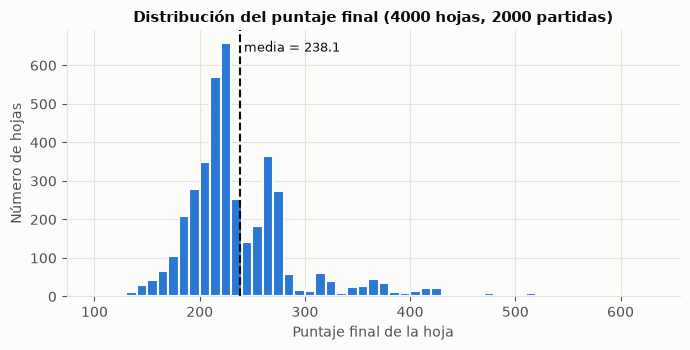

In [22]:
# 1. Distribución del puntaje final
principal = datos["principal"]
figura, eje = plt.subplots(figsize=(7, 3.6))
eje.hist(puntajes, bins=np.arange(puntajes.min() // 10 * 10, puntajes.max() + 10, 10),
         color=AZUL, edgecolor=SUPERFICIE, linewidth=1.5)
eje.axvline(principal["media"], color=TINTA, linewidth=1.5, linestyle="--")
eje.text(principal["media"] + 4, eje.get_ylim()[1] * 0.92, f"media = {principal['media']:.1f}",
         color=TINTA, fontsize=9)
eje.set_xlabel("Puntaje final de la hoja")
eje.set_ylabel("Número de hojas")
eje.set_title(f"Distribución del puntaje final ({principal['hojas']} hojas, {principal['partidas']} partidas)")
guardar(figura, "fig_distribucion.png")

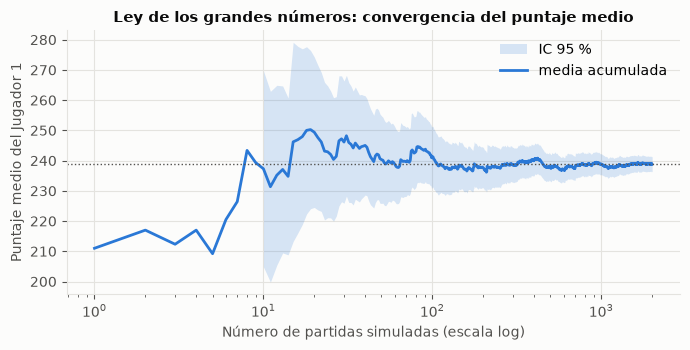

In [23]:
# 2. Convergencia de la media acumulada (Jugador 1) con IC 95 %
n = np.arange(1, len(totales_j1) + 1)
media_acumulada = np.cumsum(totales_j1) / n
desviacion_acumulada = np.array([totales_j1[:k].std(ddof=1) if k > 1 else np.nan for k in n])
semiancho = 1.96 * desviacion_acumulada / np.sqrt(n)
figura, eje = plt.subplots(figsize=(7, 3.6))
eje.fill_between(n[9:], (media_acumulada - semiancho)[9:], (media_acumulada + semiancho)[9:],
                 color=AZUL, alpha=0.18, linewidth=0, label="IC 95 %")
eje.plot(n, media_acumulada, color=AZUL, linewidth=2, label="media acumulada")
eje.axhline(totales_j1.mean(), color=TINTA_SECUNDARIA, linewidth=1, linestyle=":")
eje.set_xscale("log")
eje.set_xlabel("Número de partidas simuladas (escala log)")
eje.set_ylabel("Puntaje medio del Jugador 1")
eje.set_title("Ley de los grandes números: convergencia del puntaje medio")
eje.legend(frameon=False, loc="upper right")
guardar(figura, "fig_convergencia_media.png")

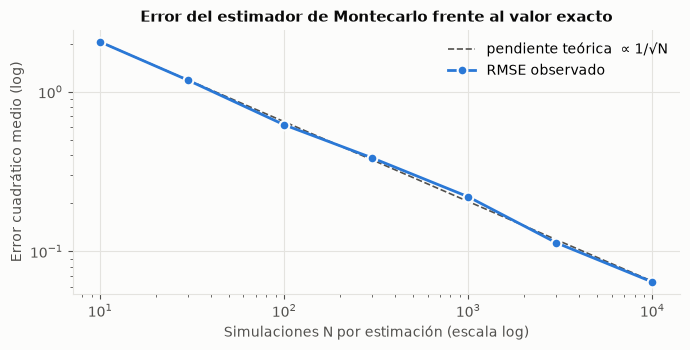

In [24]:
# 3. Error del estimador de valor vs número de simulaciones
filas = datos["convergencia"]["filas"]
tamanos = np.array([f["n"] for f in filas])
rmse = np.array([f["rmse"] for f in filas])
referencia = rmse[0] * np.sqrt(tamanos[0] / tamanos)
figura, eje = plt.subplots(figsize=(7, 3.6))
eje.plot(tamanos, referencia, color=TINTA_SECUNDARIA, linewidth=1.2, linestyle="--",
         label="pendiente teórica  ∝ 1/√N")
eje.plot(tamanos, rmse, color=AZUL, linewidth=2, marker="o", markersize=7,
         markeredgecolor=SUPERFICIE, markeredgewidth=1.5, label="RMSE observado")
eje.set_xscale("log")
eje.set_yscale("log")
eje.set_xlabel("Simulaciones N por estimación (escala log)")
eje.set_ylabel("Error cuadrático medio (log)")
eje.set_title("Error del estimador de Montecarlo frente al valor exacto")
eje.legend(frameon=False)
guardar(figura, "fig_error_estimador.png")

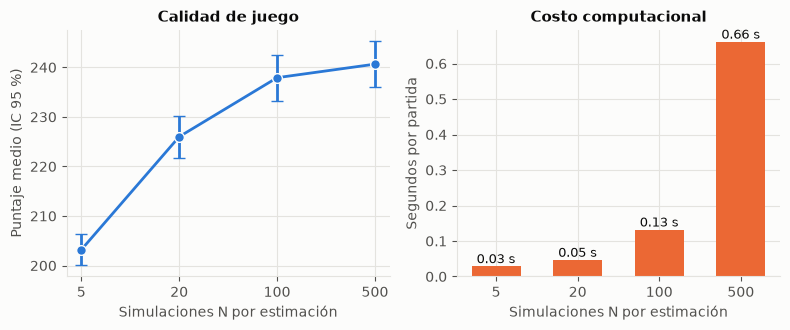

In [25]:
# 4. Sensibilidad: puntaje medio y costo (dos paneles, sin doble eje)
sens = datos["sensibilidad"]
simulaciones = [f["simulaciones"] for f in sens]
etiquetas = [str(s) for s in simulaciones]
medias = np.array([f["media"] for f in sens])
errores = np.array([f["media"] - f["ic_inferior"] for f in sens])
tiempos = np.array([f["segundos_por_partida"] for f in sens])
figura, (eje1, eje2) = plt.subplots(1, 2, figsize=(8, 3.4))
eje1.errorbar(etiquetas, medias, yerr=errores, color=AZUL, linewidth=2, marker="o",
              markersize=7, capsize=4, markeredgecolor=SUPERFICIE)
eje1.set_xlabel("Simulaciones N por estimación")
eje1.set_ylabel("Puntaje medio (IC 95 %)")
eje1.set_title("Calidad de juego")
eje2.bar(etiquetas, tiempos, color=NARANJA, width=0.6)
for posicion, valor in enumerate(tiempos):
    eje2.text(posicion, valor, f"{valor:.2f} s", ha="center", va="bottom", fontsize=9, color=TINTA)
eje2.set_xlabel("Simulaciones N por estimación")
eje2.set_ylabel("Segundos por partida")
eje2.set_title("Costo computacional")
guardar(figura, "fig_sensibilidad.png")

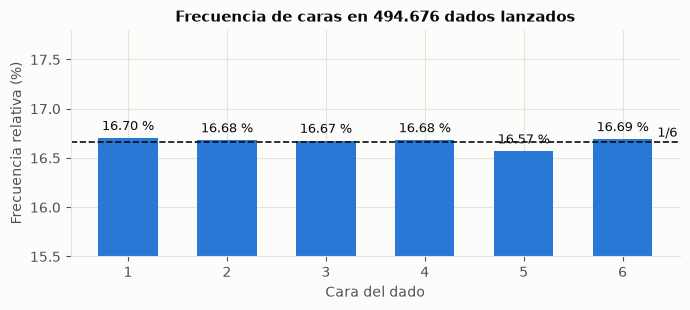

In [26]:
# 5. Frecuencia de caras
caras = np.array(principal["caras"], dtype=float)
porcentajes = 100 * caras / caras.sum()
figura, eje = plt.subplots(figsize=(7, 3.2))
eje.bar([str(c) for c in range(1, 7)], porcentajes, color=AZUL, width=0.6)
eje.axhline(100 / 6, color=TINTA, linewidth=1.2, linestyle="--")
eje.text(5.35, 100 / 6 + 0.05, "1/6", color=TINTA, fontsize=9)
for posicion, valor in enumerate(porcentajes):
    eje.text(posicion, valor + 0.05, f"{valor:.2f} %", ha="center", va="bottom", fontsize=9, color=TINTA)
eje.set_ylim(15.5, 17.8)
eje.set_xlabel("Cara del dado")
eje.set_ylabel("Frecuencia relativa (%)")
eje.set_title(f"Frecuencia de caras en {int(caras.sum()):,} dados lanzados".replace(",", "."))
guardar(figura, "fig_caras.png")

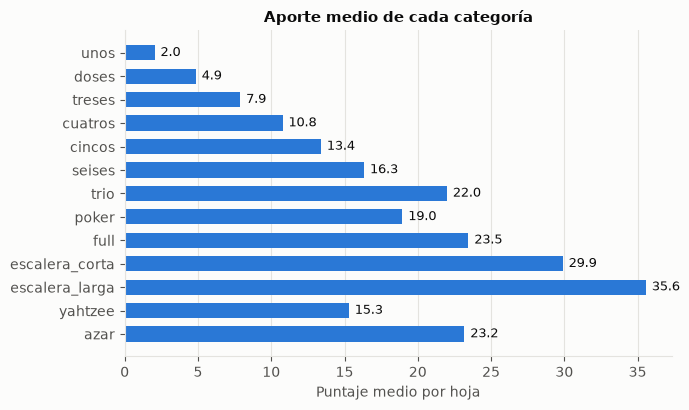

In [27]:
# 6. Puntaje medio por categoría
promedios = np.array(principal["promedio_por_categoria"])
nombres = CATEGORIAS
figura, eje = plt.subplots(figsize=(7, 4.2))
posiciones = np.arange(len(nombres))[::-1]
eje.barh(posiciones, promedios, color=AZUL, height=0.65)
for posicion, valor in zip(posiciones, promedios):
    eje.text(valor + 0.4, posicion, f"{valor:.1f}", va="center", fontsize=9, color=TINTA)
eje.set_yticks(posiciones)
eje.set_yticklabels(nombres)
eje.grid(axis="y", visible=False)
eje.set_xlabel("Puntaje medio por hoja")
eje.set_title("Aporte medio de cada categoría")
guardar(figura, "fig_categorias.png")

## 6. Resumen

In [28]:
p = salida["principal"]
print(f"Puntaje medio: {p['media']:.1f}  (IC 95 %: {p['ic_inferior']:.1f} a {p['ic_superior']:.1f})")
print(f"Victorias J1 / J2 / empates: {p['victorias_j1']} / {p['victorias_j2']} / {p['empates']}")
print(f"Hojas con bono superior: {100 * p['tasa_bono_superior']:.1f} %")
print(f"Prueba chi-cuadrado de uniformidad: chi2 = {p['chi2_caras']:.2f}, p = {p['valor_p_caras']:.3f}")
print(f"Reproducibilidad con la misma semilla: {salida['semillas']['reproducible']}")

Puntaje medio: 238.1  (IC 95 %: 236.3 a 239.8)
Victorias J1 / J2 / empates: 993 / 988 / 19
Hojas con bono superior: 17.2 %
Prueba chi-cuadrado de uniformidad: chi2 = 3.66, p = 0.599
Reproducibilidad con la misma semilla: True
